In [1]:
pip install ket-lang ket-lang[plot] -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 3.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 81.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.6/52.6 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 72.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 3.9 MB/s eta 0:00:00


In [2]:
pip install -U plotly -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 54.9 MB/s eta 0:00:00


In [3]:
from IPython.display import display
import plotly.io as pio
pio.renderers.default = "iframe"

from ket import *
import numpy as np
import matplotlib.pyplot as plt

from functools import partial
import seaborn as sns

In [4]:
def gerar_cores(lista_m, cmap='viridis'):
  '''A partir de uma lista de passos, gera as cores para cada gráfico'''
  color_map = plt.get_cmap(cmap)
  indices = np.linspace(0, 1, len(lista_m))
  return [color_map(indices[i]) for i in reversed(range(len(indices)))]

# Evolução de Hamiltoniano Unitário

Para se verificar a evolução do sistema no tempo, o mais adequado é verificar
o estado quântico gerado em vários momentos dentro de um pequeno intervalo e
plotar um gráfico com os pontos gerados.

In [22]:
# Inicia-se um processo
process = Process()

# Aloca-se um qubit (que representa o elétron) em estado |0>
electron = process.alloc()

# A evolução do Hamiltoniano é expressa por Rz(2αt), sendo α = -B.e/2m
# Unidades atômicas
m_e = 1
e = 1
B = 1
alpha = -B*e/(2*m_e)

tf = 50
t = tf/1000 # queremos simular 1000 pontos entre 0 e 50

fases = [dump(electron).get()[0]]
i = 1
while i < 1000:
  RZ(2*alpha*t, electron)         # Evolução do Hamiltoniano por t segundos, partindo do estado anterior
  fase = dump(electron).get()[0]  # dump(electron) gera o QuantumState. Dele se pode retirar as partes reais e imaginárias de |0>
  fases.append(fase)
  i = i+1

Como o estado quântico possui partes real e imaginária, para visualizá-los se
plotarão dois gráficos.

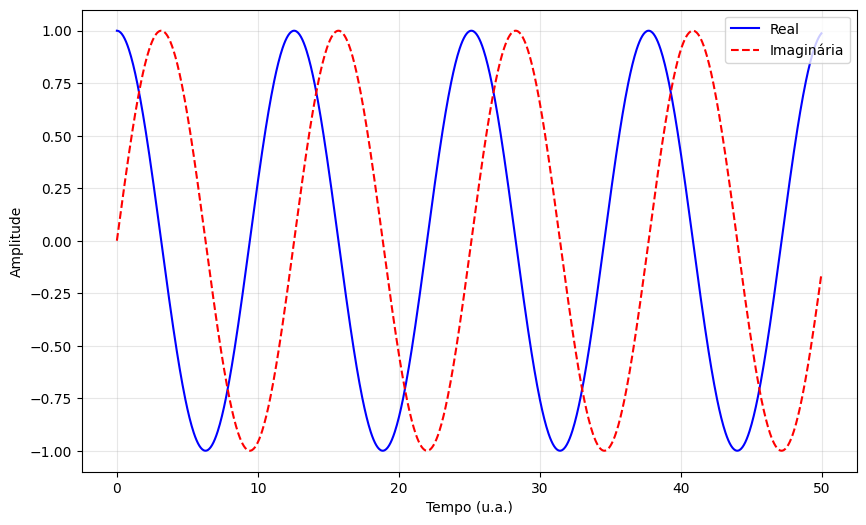

In [24]:
# Gráficos
plt.figure(figsize=(10, 6))
t = [tf*i/1000 for i in range(1000)] # multiplica-se por 1e6 para converter em mis
y = np.array(fases)

# Parte Real
plt.plot(t, y.real, label='Real', color='blue')
# Parte Imaginária
plt.plot(t, y.imag, label='Imaginária', color='red', linestyle='--')

plt.xlabel('Tempo (u.a.)')
plt.ylabel('Amplitude')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

plt.savefig('grafico_eletron.pdf')
plt.show()

---

# Evolução de Hamiltoniano via Fórmula de Produto de Lie-Trotter

A evolução de Hamiltoniano via Lie-Trotter segue que Hamiltonianos não-unitários são compostos por uma soma de operadores unitários. Se terá que, da evolução de um somatório de unitários, se pode aproximá-los em um produtório de evoluções de unitários:

$e^{-i\sum_{j}^L\alpha_jH_jt} = \prod_j^L(e^{-i\alpha_jH_jt/k})^k + \mathcal{O}(L^2t^2/k)$

Ou seja, consiga encontrar uma forma de escrever o hamiltoniano em um somatório de unitários, escreva a evolução como um produtório, construa o circuito equivalente para $t/k$ e então aplique-o $k$ vezes.

## Modelo de Ising


Um exemplo básico para demonstração é o Modelo de Ising com Campo Transversal unidimensional em uma rede de 3 spins. O Hamiltoniano é expresso:

$H = -J\sum_{⟨i,j⟩} Z_iZ_j - h\sum_iX_i = H_Z + H_X$

Esse Hamiltoniano refere-se à dinâmica de extinção desse modelo. O termo $H_Z$ corresponde à interação entre os spins vizinhos, com $J$ sendo a constante desta força de interação, enquanto o $H_X$ à interação de cada spin com o campo transversal, com $h$ sendo a constante da força do campo.

 Aplicar a Fórmula de Produto de Lie-Trotter nesse Hamiltoniano pode ser feito em etapas.

1) Aplicando em $H_Z + H_X$

A evolução do hamiltoniano de Ising é expressa pelo operador $U = e^{-iHt}$, e $H = H_Z + H_X$. Logo, considerando o número de passos $k$, ao se aplicar a fórmula se obterá a seguinte aproximação:

$U \approx (e^{-iH_Zt/k}e^{-iH_Xt/k})^k$

2) Aplicando em cada hamiltoniano da soma

- Para $H_Z$:

$e^{-iH_Zt} = e^{iJ\sum_{⟨i,j⟩} Z_iZ_jt}$

$e^{-iH_Zt} \approx (\prod_{⟨i,j⟩} e^{iJZ_iZ_jt/k})^k$

- Para $H_X$:

$e^{-iH_xt} = e^{ih\sum_iX_it}$

$e^{-iH_xt} \approx (\prod_i e^{iX_it/k})^k$

3) Juntando numa expressão:

$U \approx (\prod_{⟨i,j⟩} e^{iJZ_iZ_jt/k}\prod_i e^{iX_it/k})^k$

4) Agora se tem o produtório de evolução de unitários. Já se foi visto o procedimento de transformar evoluções de unitários em portas lógicas quânticas. Logo esses termos se transformam em:

$U \approx (\prod_{⟨i,j⟩} R_{ZZ}(-2Jt/k)\prod_i R_X(-2ht/k))^k$

## Montagem do circuito

A rede de 3 spins unidimensional significa que ambos estão dispostos em linha, então, considerando os spins de 0 a 2, as únicas interações que ocorrerão serão entre 0 e 1, e entre 1 e 2, segundo a imagem:

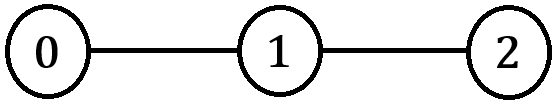

Representa-se essa rede de spins em 3 qubits. O primeiro produtório corresponderá a interação do spin 0 e 1 e a interação do spin 1 e 2, logo, $R_{ZZ}$ entre os qubits 0 e 1 e $R_{ZZ}$ entre os qubits 1 e 2. O segundo produtório significa $R_X$ em cada um dos qubits.

Logo, o circuito para um tempo $t/k$ é dado:

In [8]:
J = 0.1   # Força de interação entre spins
h = 1     # Força de campo
m = 5     # Número de passos de Trotter
t = 15     # Tempo de execução

In [9]:
process = Process()

q0, q1, q2 = process.alloc(3)

def ising_3q_tm(q0, q1, q2, m, J, h, t):
  RX(-2*h*t/m, q0)
  RX(-2*h*t/m, q1)
  RX(-2*h*t/m, q2)
  RZZ(-2*J*t/m, q0,q1)
  RZZ(-2*J*t/m, q1,q2)

def ising_3q(q0, q1, q2):
  for _ in range(m):
    ising_3q_tm(q0,q1,q2,m, J, h, t)

ising_3q(q0, q1, q2)

dump(q0+q1+q2).show()

<IPython.core.display.Math object>

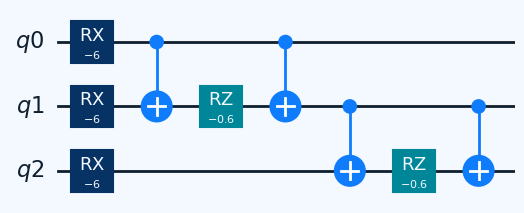

In [10]:
# Representação para um passo
ising_3q_1passo = partial(ising_3q_tm, m=m,J=J,h=h,t=t)
qulib.draw(ising_3q_1passo, (1,1,1))

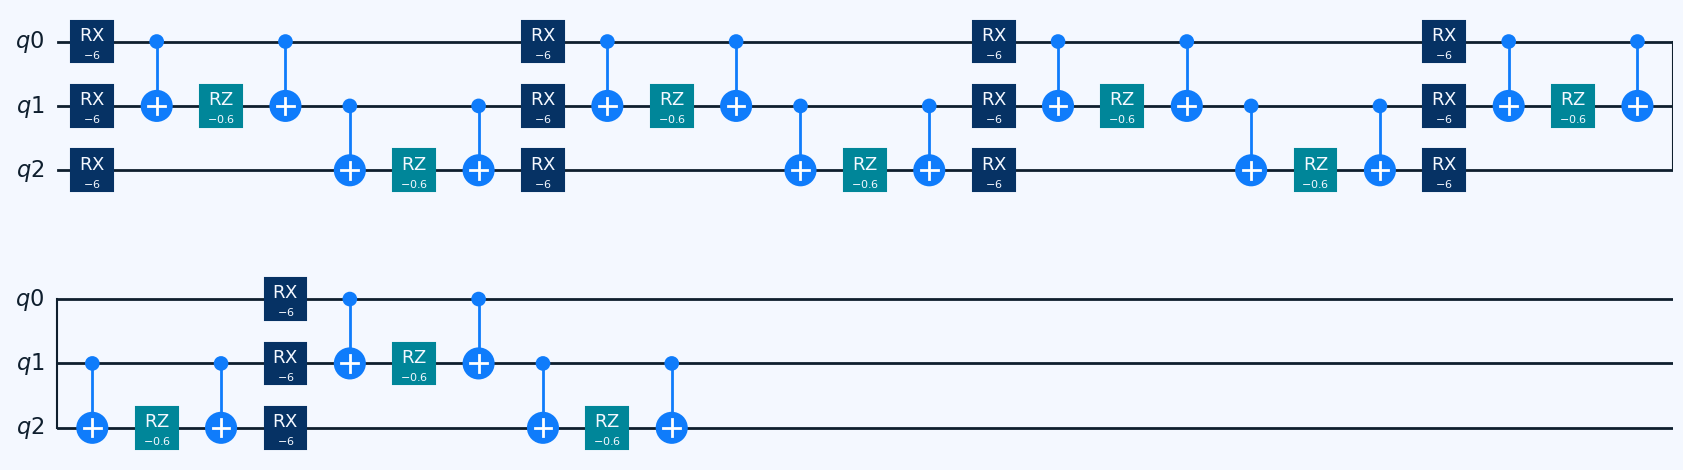

In [11]:
# Representação para os 5 passos
qulib.draw(ising_3q, (1,1,1))

O valor de interesse ao se analisar a evolução temporal do modelo de Ising de campo transverso é a magnetização média ⟨Z⟩ em função do tempo (ou número de passos de Trotter), conforme vemos [nessa referência](https://quantum.cloud.ibm.com/docs/pt/tutorials/transverse-field-ising-model
). O que se espera é que a magnetização tenha um padrão oscilatório amortecido.

## Evolução de $t_0$ a $t_f$

In [20]:
def evolucao_ising_t(state, spin_graph, params, t, m):
  '''
  Executa a evolução do Hamiltoniano de Ising em um t. A ser utilizada
  em conjunto com a `evolucao_ni_ising`.
  Como está em Ket, executar a evolução de `state` altera `state` para o estado
  evoluído, logo, é necessário criar processos e estados iniciais novos repetidas
  vezes

  Parâmetros:
  state (ket.base.Quant): Estado do sistema, uma lista de qubits (spins)
  spin_graph (list): Uma lista de pares de índices, que indica vizinhança entre
  spins e diferencia redes de spin de mesmo tamanho
  params (list): Parâmetros do sistema, um iterável ordenado [J, h], sendo o primeiro a
  força de interação entre spins e o segundo a força do campo
  t (float): tempo
  m (int): Número de passos de Trotter
  '''
  J, h = params
  for _ in range(m):
    for single_qubit in state:
      RX(-2*h*t/m, single_qubit)
    for pair in spin_graph:
      RZZ(-2*J*t/m, state[pair[0]], state[pair[1]])

def evolucao_ni_ising(spin_graph, params, m, Dt, tf, t0=0):
  '''
  Executa a função de evolução em um t + n*Delta t de t0 até tf, incrementando t em
  Delta t ao final de cada iteração, até que tf seja atingido.
  Ao final de cada evolução em t, calcula-se o valor esperado em relação a Z
  dos estados (magnetização) e posteriormente a média deles (magnetização média)
  e armazena numa lista, a ser retornada junto do estado evoluído ao final

  Parâmetros:
  spin_graph (list): Uma lista de pares de índices, que indica vizinhança entre
  spins e diferencia redes de spin de mesmo tamanho
  params (list): Parâmetros do sistema, um iterável ordenado [J, h], sendo o primeiro a
  força de interação entre spins e o segundo a força do campo
  m (int): Número de passos de Trotter
  Dt (float): Passo para geração de gráfico
  tf (float): Tempo final de evolução, desobedecido caso não divisível por Dt
  t0 (float): Tempo inicial de evolução, deve corresponder a init_state
  '''
  t = t0

  def add_mag_to_list(state, magmed_list):
    mag = []
    for spin in state:
      with obs():
        z_spin = Z(spin)
      ev_z_spin = exp_value(z_spin).get()
      mag.append(ev_z_spin)

    magmed = sum(mag)/len(mag)
    magmed_list.append(magmed)
    return magmed_list

  magmed_list = []

  while t <= tf:
    p = Process()
    state = p.alloc(3)
    evolucao_ising_t(state, spin_graph, params, t, m)
    magmed_list = add_mag_to_list(state, magmed_list)
    t = t + Dt

  return magmed_list

In [21]:
def grafico_evolucao_ni(color, spin_graph, params, m, Dt, tf, t0=0):
  magmed_list = evolucao_ni_ising(spin_graph, params, m, Dt, tf, t0)

  t = t0
  times = []
  while t < tf:
    times.append(t+Dt)
    t = t + Dt
  y = magmed_list

  plt.plot(times, y, color=color, label=f'{m} passos')
  plt.axis([0,t,-1,1])
  plt.xlabel('Tempo (s)')
  plt.ylabel('Magnetização ⟨Z⟩')
  plt.grid(True, alpha=0.3)
  plt.legend()

  plt.savefig(f"grafico_ising_{m}.pdf")
  plt.draw()

In [22]:
def evolucoes_ni(lista_m, spin_graph, params, Dt, tf, t0=0, cmap='gist_rainbow'):
  '''A partir de uma lista de valores de m, faz um gráfico com tudo junto'''
  lista_cores = gerar_cores(lista_m, cmap)
  plt.ion()
  plt.figure(figsize=(10, 6))
  for i in range(len(lista_m)):
    grafico_evolucao_ni(lista_cores[i], spin_graph, params, lista_m[i], Dt, tf, t0)
  plt.savefig(f"grafico_ising_{len(lista_m)}vals.pdf")
  plt.show()

In [27]:
spin_graph  = [(0,1), (1,2)] # considerando rede unidimensional de 3 spins
params      = [0.1, 1]       # [J,h]
# tempo inicial = 0
tf          = 25           #tempo final
Dt          = tf/1000       # \Delta t

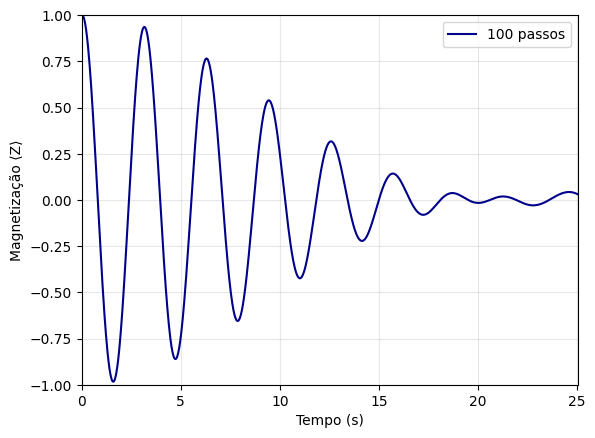

In [29]:
grafico_evolucao_ni("darkblue", spin_graph, params, 100, Dt, tf)

In [31]:
lista_m = [2, 10, 15, 50, 150]

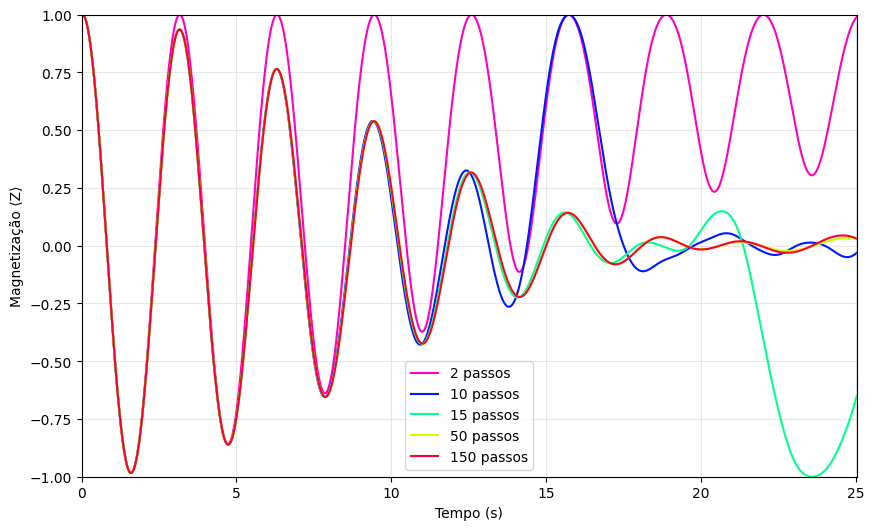

In [ ]:
evolucoes_ni(lista_m, spin_graph, params, Dt, tf)

Podemos ver a influência do tempo em relação ao número de passos utilizado. O que se observa neste gráfico é que, em qualquer passo, o gráfico será comportado (e com erros próximos de zero) até que se chegue um certo valor de t, em que ele começa a desviar e a ter um comportamento estranho.

Quando vamos evoluir um sistema com hamiltoniano definido, definimos um estado inicial $|\psi_0\rangle$ e um $t_f$, construímos a unitária $U_m(t)$ que corresponde ao Lie-Trotter com seus $m$ passos de Trotter, e então aplicamos $U_m(t_f)|\psi_0\rangle$ para gerar o $|\psi_f\rangle$. Esse gráfico mostra, então, que de acordo com o valor de $t_f$ e de $m$ que o usuário escolher, o estado final resultante pode ser bem nada a ver.

---

## Obtenção de $t_{crit}$ para cada $m$

Para cada $m$, o $t_{crit}$ é aquele em que o erro associado ao valor de magnetização média passa de um certo limiar $\epsilon$. Esse valor é comparado com o suposto valor de magnetização média analítico, que corresponde à execução do circuito com um número grande de passos de Trotter.

O código abaixo é uma adaptação de um código anterior, mas agora o critério de parada não é um $t_f$, mas justamente a condição da diferença entre a magnetização média obtida pelo circuito com $m$ passos e obtida por um circuito com um número grande.

Neste caso, verifiquemos utilizando o circuito analítico aquele com $m = 150$, e verifiquemos a relação $m$ e $t_{crit}$ de 1 até 100 passos, com $\epsilon = 0.01$

In [32]:
def evolucao_tcrit(spin_graph, params, m, Dt, epsilon, magmed_list_analitic, t0=0):
  '''
  Executa a função de evolução em um t + n*Delta t de t0 até tf, incrementando t em
  Delta t ao final de cada iteração, até que tf seja atingido.
  Ao final de cada evolução em t, calcula-se o valor esperado em relação a Z
  dos estados (magnetização) e posteriormente a média deles (magnetização média)
  e armazena numa lista, a ser retornada junto do estado evoluído ao final

  Parâmetros:
  spin_graph (list): Uma lista de pares de índices, que indica vizinhança entre
  spins e diferencia redes de spin de mesmo tamanho
  params (list): Parâmetros do sistema, um iterável ordenado [J, h], sendo o primeiro a
  força de interação entre spins e o segundo a força do campo
  m (int): Número de passos de Trotter
  Dt (float): Passo para geração de gráfico
  epsilon (float): Limiar de magnetização
  magmed_list_analitic (list): Lista de magnetizações médias do circuito analítico.
  Estamos fazendo isso pois queremos analisar vários m's, não quero fazer essa
  mesma evolução várias vezes.
  t0 (float): Tempo inicial de evolução, deve corresponder a init_state

  Retorno:
  tuple: Par (m, t_crit)
  '''
  t = t0

  def get_magmed(state):
    mag = []
    for spin in state:
      with obs():
        z_spin = Z(spin)
      ev_z_spin = exp_value(z_spin).get()
      mag.append(ev_z_spin)

    magmed = sum(mag)/len(mag)
    return magmed

  diff = 0
  i = 0

  while True:
    if i > len(magmed_list_analitic):
      print('A evolução analítica foi executada por tempo curto demais')
      break
    p = Process()
    state = p.alloc(3)
    evolucao_ising_t(state, spin_graph, params, t, m)
    magmed = get_magmed(state)
    diff = abs(magmed - magmed_list_analitic[i])
    if diff > epsilon:
      break
    t = t + Dt
    i = i + 1

  print(f'{m} passos: tcrit em {round(t,2)} segundos')
  return (m,t)

In [33]:
spin_graph  = [(0,1), (1,2)] # considerando rede unidimensional de 3 spins
params      = [0.1, 1]       # [J,h]
# tempo inicial = 0
tf          = 60           #tempo final
Dt          = tf/1000       # \Delta t

In [35]:
# Problema: necessita-se gerar uma evolução em um tempo longo o suficiente para
# cobrir a evolução do maior m a ser testado. Neste caso vou tentar 300s
# Em execuções anteriores percebi que os valores de tempo não passam de 40s, então
# vou executar por apenas por 50s
magmed_list_analitic = evolucao_ni_ising(spin_graph, params, 150, Dt, tf)

In [36]:
# Teste: espera-se que a evolução em 20 passos tenha t_crit lá pelos 20s,
# então o retorno esperado é (20, ~20)
epsilon = 0.02
m = 20
print(evolucao_tcrit(spin_graph, params, m, Dt, epsilon, magmed_list_analitic))

20 passos: tcrit em 20.82 segundos
(20, 20.81999999999994)


In [37]:
# Agora para traçarmos o gráfico de 1 a 100 passos:
tcrit_list = []
m_list = list(range(1,101))
for m in m_list:
  _, tcrit = evolucao_tcrit(spin_graph, params, m, Dt, epsilon, magmed_list_analitic)
  tcrit_list.append(tcrit)

1 passos: tcrit em 2.52 segundos
2 passos: tcrit em 2.16 segundos
3 passos: tcrit em 3.42 segundos
4 passos: tcrit em 3.72 segundos
5 passos: tcrit em 5.04 segundos
6 passos: tcrit em 5.22 segundos
7 passos: tcrit em 5.46 segundos
8 passos: tcrit em 6.72 segundos
9 passos: tcrit em 6.84 segundos
10 passos: tcrit em 8.22 segundos
11 passos: tcrit em 8.34 segundos
12 passos: tcrit em 8.52 segundos
13 passos: tcrit em 9.9 segundos
14 passos: tcrit em 10.02 segundos
15 passos: tcrit em 11.46 segundos
16 passos: tcrit em 11.58 segundos
17 passos: tcrit em 13.14 segundos
18 passos: tcrit em 19.68 segundos
19 passos: tcrit em 19.74 segundos
20 passos: tcrit em 20.82 segundos
21 passos: tcrit em 20.82 segundos
22 passos: tcrit em 20.88 segundos
23 passos: tcrit em 20.88 segundos
24 passos: tcrit em 20.94 segundos
25 passos: tcrit em 21.0 segundos
26 passos: tcrit em 21.12 segundos
27 passos: tcrit em 22.32 segundos
28 passos: tcrit em 22.38 segundos
29 passos: tcrit em 22.38 segundos
30 passos

/tmp/ipykernel_4412/2586983871.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


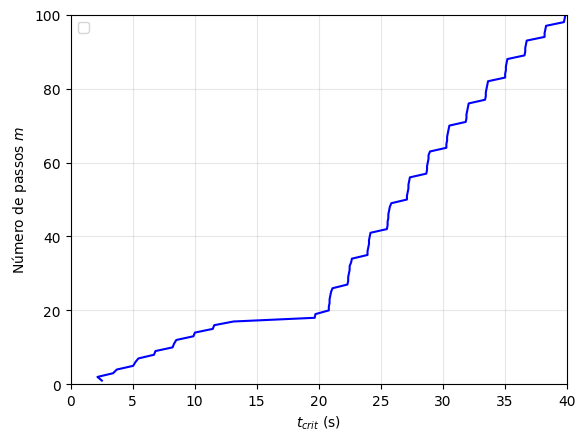

In [38]:
plt.plot(tcrit_list, m_list, color="blue")
plt.axis([0,40,0,100])
plt.xlabel('$t_{crit}$ (s)')
plt.ylabel('Número de passos $m$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig(f"grafico_tcrit.pdf")
plt.draw()


In [39]:
# Teste 2 : Vejo que o gráfico ficou meio estranho entre 15 a 20 passos, teve um
# salto súbito. Vou testar um valor menor de passos com um epsilon um pouco maior
epsilon = 0.04
tcrit_list_2 = []
m_list_2 = list(range(1,41))
for m in m_list_2:
  _, tcrit = evolucao_tcrit(spin_graph, params, m, Dt, epsilon, magmed_list_analitic)
  tcrit_list_2.append(tcrit)

1 passos: tcrit em 2.76 segundos
2 passos: tcrit em 2.52 segundos
3 passos: tcrit em 3.6 segundos
4 passos: tcrit em 4.98 segundos
5 passos: tcrit em 5.28 segundos
6 passos: tcrit em 6.66 segundos
7 passos: tcrit em 6.9 segundos
8 passos: tcrit em 8.28 segundos
9 passos: tcrit em 8.46 segundos
10 passos: tcrit em 9.9 segundos
11 passos: tcrit em 10.08 segundos
12 passos: tcrit em 11.52 segundos
13 passos: tcrit em 13.08 segundos
14 passos: tcrit em 14.76 segundos
15 passos: tcrit em 18.78 segundos
16 passos: tcrit em 19.8 segundos
17 passos: tcrit em 19.98 segundos
18 passos: tcrit em 21.06 segundos
19 passos: tcrit em 21.06 segundos
20 passos: tcrit em 21.12 segundos
21 passos: tcrit em 21.3 segundos
22 passos: tcrit em 22.44 segundos
23 passos: tcrit em 22.5 segundos
24 passos: tcrit em 22.56 segundos
25 passos: tcrit em 22.62 segundos
26 passos: tcrit em 22.74 segundos
27 passos: tcrit em 24.0 segundos
28 passos: tcrit em 24.06 segundos
29 passos: tcrit em 24.06 segundos
30 passos: 

/tmp/ipykernel_6429/3430024519.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


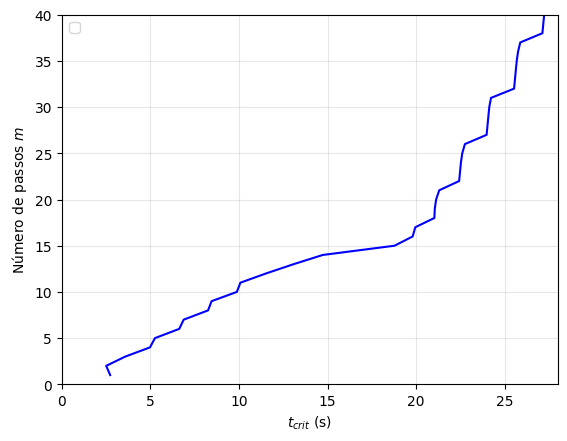

In [ ]:
plt.plot(tcrit_list_2, m_list_2, color="blue")
plt.axis([0,28,0,40])
plt.xlabel('$t_{crit}$ (s)')
plt.ylabel('Número de passos $m$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig(f"grafico_tcrit.pdf")
plt.draw()

### Para vários valores de $\epsilon$

In [ ]:
def evolucao_tcrit_epsilons(spin_graph, params, m, Dt, valores_epsilon, magmed_list_analitic, t0=0):
  '''
  Executa a função de evolução em um t + n*Delta t de t0 até tf, incrementando t em
  Delta t ao final de cada iteração, até que tf seja atingido.
  Ao final de cada evolução em t, calcula-se o valor esperado em relação a Z
  dos estados (magnetização) e posteriormente a média deles (magnetização média)
  e armazena numa lista, a ser retornada junto do estado evoluído ao final

  Parâmetros:
  spin_graph (list): Uma lista de pares de índices, que indica vizinhança entre
  spins e diferencia redes de spin de mesmo tamanho
  params (list): Parâmetros do sistema, um iterável ordenado [J, h], sendo o primeiro a
  força de interação entre spins e o segundo a força do campo
  m (int): Número de passos de Trotter
  Dt (float): Passo para geração de gráfico
  valores_epsilon (list): Lista de limiares de magnetização
  magmed_list_analitic (list): Lista de magnetizações médias do circuito analítico.
  Estamos fazendo isso pois queremos analisar vários m's, não quero fazer essa
  mesma evolução várias vezes.
  t0 (float): Tempo inicial de evolução, deve corresponder a init_state

  Retorno:
  tuple: Par (m, t_crit)
  '''
  t = t0

  def get_magmed(state):
    mag = []
    for spin in state:
      with obs():
        z_spin = Z(spin)
      ev_z_spin = exp_value(z_spin).get()
      mag.append(ev_z_spin)

    magmed = sum(mag)/len(mag)
    return magmed

  valores_epsilon.sort()
  i_ep = 0
  epsilon = valores_epsilon[i_ep]

  tcrits = {}

  diff = 0
  i = 0
  while True:
    if i == len(magmed_list_analitic):
      print('A evolução analítica foi executada por tempo curto demais')
      break
    p = Process()
    state = p.alloc(3)
    evolucao_ising_t(state, spin_graph, params, t, m)
    magmed = get_magmed(state)
    diff = abs(magmed - magmed_list_analitic[i])
    while i_ep < len(valores_epsilon) and diff > valores_epsilon[i_ep]:
      tcrits[valores_epsilon[i_ep]] = t
      i_ep = i_ep + 1
    if i_ep == len(valores_epsilon):
      break
    t = t + Dt
    i = i + 1

  return tcrits

In [ ]:
evolucao_tcrit_epsilons(spin_graph, params, 20, Dt, [0.01, 0.02, 0.03, 0.04, 0.05], magmed_list_analitic)

{0.01: 10.199999999999996,
 0.02: 20.81999999999994,
 0.03: 20.999999999999936,
 0.04: 21.119999999999933,
 0.05: 22.499999999999904}

In [ ]:
def tcrits_to_graphic(spin_graph, params, m_list, Dt, valores_epsilon, magmed_list_analitic, t0=0):
  tcrits_lists = {}
  for ep in valores_epsilon:
    tcrits_lists[ep] = []

  for m in m_list:
    tcrits = evolucao_tcrit_epsilons(spin_graph, params, m, Dt, valores_epsilon, magmed_list_analitic, t0)
    for ep in tcrits:
      tcrits_lists[ep].append(tcrits[ep])

  return tcrits_lists

In [ ]:
# Agora para traçarmos o gráfico de 1 a 100 passos:
valores_epsilon = [0.01, 0.02, 0.03, 0.04, 0.05]
m_list = list(range(1,61))
tcrits_lists = tcrits_to_graphic(spin_graph, params, m_list, Dt, valores_epsilon, magmed_list_analitic)

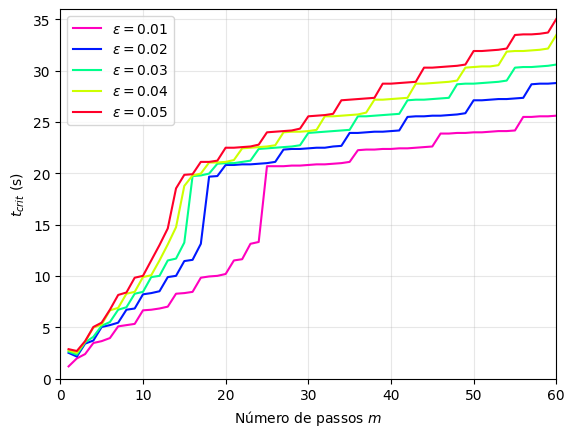

In [ ]:
lista_cores = gerar_cores(tcrits_lists, "gist_rainbow")

plt.ion()
for i, ep in enumerate(tcrits_lists):
  plt.plot(m_list, tcrits_lists[ep], color=lista_cores[i], label=f'$\\epsilon = {ep}$')
plt.axis([0,60,0,36])
plt.ylabel('$t_{crit}$ (s)')
plt.xlabel('Número de passos $m$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig(f"grafico_tcrit.pdf")
plt.draw()

